# La matemática de las funciones de pérdida

Las funciones de pérdida suelen presentarse como una lista de recetas: MSE para regresión, entropía cruzada para clasificación. Este notebook muestra que todas salen de **un mismo principio**, la máxima verosimilitud, y que lo que cambia de una a otra es la suposición sobre cómo se generan los datos.

Para cada pérdida: la fórmula, su deducción, su gradiente, y una versión a mano comprobada contra PyTorch.

**Contenido**

1. El principio: máxima verosimilitud
2. `MSELoss`: ruido gaussiano
3. `L1Loss`: ruido de Laplace, y por qué resiste valores atípicos
4. `HuberLoss`: un punto intermedio
5. `BCELoss`: una moneda cargada
6. `BCEWithLogitsLoss`: la misma pérdida, calculada con cuidado
7. `CrossEntropyLoss`: varias clases
8. El gradiente de la entropía cruzada
9. Entropía cruzada binaria como caso particular
10. Resumen y ejercicios

In [1]:
import math

import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. El principio: máxima verosimilitud

Un modelo con parámetros $\theta$ no tiene por qué entregar solo un número. Se puede pensar que entrega una **distribución de probabilidad** sobre la etiqueta: dado $x$, qué tan probable es cada valor posible de $y$. Lo escribimos $p(y \mid x; \theta)$.

Con esa lectura hay un criterio natural para elegir $\theta$: preferir los parámetros bajo los cuales **los datos que realmente observamos resultan más probables**. Si los ejemplos son independientes, la probabilidad de todos juntos es el producto, llamado **verosimilitud**:

$$\mathcal{L}(\theta) = \prod_{i=1}^{N} p(y_i \mid x_i; \theta)$$

Un producto de muchos números pequeños es incómodo (numéricamente tiende a cero). Como el logaritmo es creciente, maximizar $\mathcal{L}$ equivale a maximizar $\log \mathcal{L}$, que convierte el producto en suma. Y como los optimizadores minimizan, se le cambia el signo. Queda la **log-verosimilitud negativa** (NLL), promediada sobre los datos:

$$\text{NLL}(\theta) = -\frac{1}{N} \sum_{i=1}^{N} \log p(y_i \mid x_i; \theta)$$

Toda función de pérdida de este notebook es esta expresión para una elección particular de $p$, salvo constantes que no cambian dónde está el mínimo.

| Suposición sobre $y$ dado $x$ | Pérdida resultante |
|---|---|
| Gaussiana centrada en la predicción | `MSELoss` |
| Laplace centrada en la predicción | `L1Loss` |
| Bernoulli (dos resultados) | `BCELoss` |
| Categórica ($C$ resultados) | `CrossEntropyLoss` |

## 2. `MSELoss`: ruido gaussiano

**Fórmula.** Con `reduction="mean"`, que es el valor por omisión, promedia sobre **todos los elementos** del tensor:

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2$$

**Deducción.** Supón que la etiqueta es la predicción del modelo más un error gaussiano de media cero y desviación $\sigma$: $y = \hat{y} + \varepsilon$, con $\varepsilon \sim \mathcal{N}(0, \sigma^2)$. Entonces

$$p(y \mid x; \theta) = \frac{1}{\sqrt{2 \pi \sigma^2}} \exp\left( -\frac{(y - \hat{y})^2}{2 \sigma^2} \right)$$

y su logaritmo negativo es

$$-\log p(y \mid x; \theta) = \frac{(y - \hat{y})^2}{2 \sigma^2} + \frac{1}{2} \log(2 \pi \sigma^2)$$

El segundo término no depende de $\theta$, y el factor $1 / (2\sigma^2)$ es una constante positiva. Ninguno cambia dónde está el mínimo. Lo que queda es el error al cuadrado: **minimizar el MSE es hacer máxima verosimilitud suponiendo ruido gaussiano**.

**Gradiente** respecto de cada predicción:

$$\frac{\partial \, \text{MSE}}{\partial \hat{y}_i} = \frac{2}{n} (\hat{y}_i - y_i)$$

Es proporcional al error: los errores grandes empujan más fuerte.

In [2]:
prediccion = torch.randn(4, 3, requires_grad=True)
objetivo = torch.randn(4, 3)

mse_a_mano = ((prediccion - objetivo) ** 2).sum() / prediccion.numel()
mse = nn.MSELoss()(prediccion, objetivo)
mse.backward()

grad_a_mano = 2 * (prediccion - objetivo) / prediccion.numel()

print("MSE a mano:", mse_a_mano.item(), "  nn.MSELoss:", mse.item())
print("¿gradiente = 2(ŷ - y)/n?", torch.allclose(grad_a_mano, prediccion.grad))

MSE a mano: 2.2558758859248784   nn.MSELoss: 2.2558758859248784
¿gradiente = 2(ŷ - y)/n? True


El argumento `reduction` controla el paso final. `"sum"` suma sin dividir, y `"none"` devuelve el error de cada elemento sin agregarlos:

In [3]:
con_suma = nn.MSELoss(reduction="sum")(prediccion, objetivo)
sin_reducir = nn.MSELoss(reduction="none")(prediccion, objetivo)

print("reduction='sum' :", con_suma.item(), "  = mean × n:", (mse * prediccion.numel()).item())
print("reduction='none': forma", tuple(sin_reducir.shape))

reduction='sum' : 27.070510631098543   = mean × n: 27.070510631098543
reduction='none': forma (4, 3)


## 3. `L1Loss`: ruido de Laplace, y por qué resiste valores atípicos

**Fórmula.**

$$\text{L1} = \frac{1}{n} \sum_{i=1}^{n} \lvert \hat{y}_i - y_i \rvert$$

**Deducción.** Es la misma cuenta de la sección anterior, cambiando la gaussiana por una distribución de **Laplace**, $p(y) \propto \exp(-\lvert y - \hat{y} \rvert / s)$, que tiene colas más pesadas: considera más probables los errores grandes. Su logaritmo negativo es $\lvert y - \hat{y} \rvert / s$ más una constante.

**Gradiente.**

$$\frac{\partial \, \text{L1}}{\partial \hat{y}_i} = \frac{1}{n} \, \text{signo}(\hat{y}_i - y_i)$$

Aquí está la diferencia práctica con el MSE: el gradiente tiene siempre la **misma magnitud**, sin importar el tamaño del error. Un dato absurdamente lejano empuja igual que uno cercano.

Hay una forma concreta de ver la consecuencia. Supón que el modelo solo puede predecir una constante $c$ para todos los datos. ¿Qué constante minimiza cada pérdida?

- Para el MSE, derivando e igualando a cero: $\sum_i (c - y_i) = 0$, de donde $c$ es la **media**.
- Para L1, la derivada es $\sum_i \text{signo}(c - y_i)$: la cantidad de datos que quedan por debajo de $c$ menos la de los que quedan por encima. La pérdida deja de bajar cuando las dos cantidades se equilibran, y eso ocurre en la **mediana**. (El valor absoluto no es derivable justo sobre un dato, así que el argumento riguroso usa subgradientes; la conclusión es la misma.)

Lo verificamos con datos que incluyen un valor atípico, evaluando ambas pérdidas en una grilla de constantes:

In [4]:
datos = torch.tensor([1.0, 2.0, 3.0, 4.0, 100.0])           # el 100 es un valor atípico

constantes = torch.linspace(0, 110, 11001)                  # candidatos, de 0.01 en 0.01
errores = constantes.unsqueeze(1) - datos                   # forma [11001, 5]

mejor_mse = constantes[(errores ** 2).mean(dim=1).argmin()]
mejor_l1 = constantes[errores.abs().mean(dim=1).argmin()]

print(f"Constante que minimiza el MSE: {mejor_mse:.2f}   (media de los datos   = {datos.mean():.2f})")
print(f"Constante que minimiza L1    : {mejor_l1:.2f}   (mediana de los datos = {datos.median():.2f})")

Constante que minimiza el MSE: 22.00   (media de los datos   = 22.00)
Constante que minimiza L1    : 3.00   (mediana de los datos = 3.00)


Un solo valor atípico arrastra la solución del MSE hasta 22, lejos de cuatro de los cinco datos. La de L1 se queda en 3. Por eso L1 se usa cuando los datos tienen errores groseros que no se quieren seguir.

El costo es que el valor absoluto tiene una esquina en cero: el gradiente no se achica al acercarse al mínimo, y la optimización tiende a oscilar alrededor de él.

In [5]:
l1_a_mano = (prediccion - objetivo).abs().mean()

prediccion.grad = None
l1 = nn.L1Loss()(prediccion, objetivo)
l1.backward()

print("L1 a mano:", l1_a_mano.item(), "  nn.L1Loss:", l1.item())
print("¿gradiente = signo(ŷ - y)/n?", torch.allclose(torch.sign(prediccion - objetivo) / prediccion.numel(), prediccion.grad))

L1 a mano: 1.3630151515861062   nn.L1Loss: 1.3630151515861062
¿gradiente = signo(ŷ - y)/n? True


## 4. `HuberLoss`: un punto intermedio

La pérdida de Huber combina las dos anteriores. Con $e = \hat{y} - y$ y un umbral $\delta$:

$$\text{Huber}_\delta(e) = \begin{cases} \frac{1}{2} e^2 & \text{si } \lvert e \rvert \le \delta \\[1ex] \delta \left( \lvert e \rvert - \frac{1}{2} \delta \right) & \text{si } \lvert e \rvert > \delta \end{cases}$$

Es cuadrática para errores pequeños (gradiente que se achica cerca del mínimo, como el MSE) y lineal para errores grandes (gradiente acotado, como L1). Las constantes están elegidas para que las dos piezas empalmen con el mismo valor y la misma pendiente en $\lvert e \rvert = \delta$: en ese punto ambas valen $\frac{1}{2} \delta^2$ y tienen pendiente de magnitud $\delta$.

Huber a mano: 0.8923961322923937   nn.HuberLoss: 0.8923961322923937


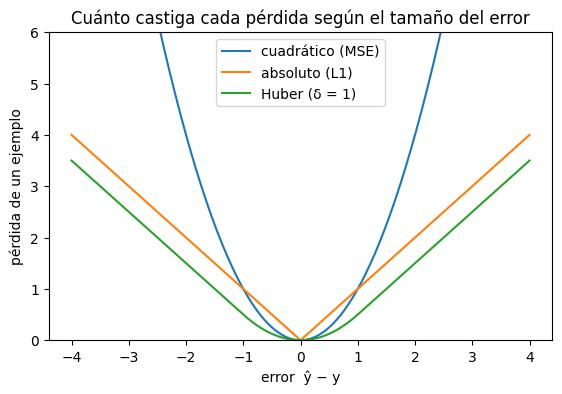

In [6]:
delta = 1.0
e = prediccion.detach() - objetivo

huber_a_mano = torch.where(e.abs() <= delta,
                           0.5 * e ** 2,
                           delta * (e.abs() - 0.5 * delta)).mean()

print("Huber a mano:", huber_a_mano.item(), "  nn.HuberLoss:", nn.HuberLoss(delta=delta)(prediccion, objetivo).item())

error = torch.linspace(-4, 4, 400)
plt.figure(figsize=(6.5, 4))
plt.plot(error, error ** 2, label="cuadrático (MSE)")
plt.plot(error, error.abs(), label="absoluto (L1)")
plt.plot(error, torch.where(error.abs() <= delta, 0.5 * error ** 2, delta * (error.abs() - 0.5 * delta)), label="Huber (δ = 1)")
plt.ylim(0, 6)
plt.xlabel("error  ŷ − y")
plt.ylabel("pérdida de un ejemplo")
plt.title("Cuánto castiga cada pérdida según el tamaño del error")
plt.legend()
plt.show()

## 5. `BCELoss`: una moneda cargada

En clasificación binaria la etiqueta es $y \in \{0, 1\}$ y el modelo entrega $p \in (0, 1)$, la probabilidad que le asigna a la clase 1.

**Deducción.** La distribución de un resultado con dos opciones es la de **Bernoulli**: $y$ vale 1 con probabilidad $p$ y 0 con probabilidad $1 - p$. Las dos situaciones se escriben en una sola expresión:

$$p(y \mid x; \theta) = p^{\,y} \, (1 - p)^{\,1 - y}$$

Si $y = 1$ queda $p$; si $y = 0$ queda $1 - p$. Su logaritmo negativo es la **entropía cruzada binaria**:

$$\text{BCE} = -\frac{1}{n} \sum_{i=1}^{n} \Big[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \Big]$$

Para cada ejemplo solo uno de los dos términos está activo: la pérdida es $-\log$ de **la probabilidad que el modelo le dio a la respuesta correcta**. Si esa probabilidad es 1, la pérdida es 0. Si se acerca a 0, la pérdida crece sin límite: equivocarse con mucha seguridad se castiga muy fuerte.

In [7]:
probabilidad = torch.tensor([0.9, 0.2, 0.6, 0.99])          # lo que entrega el modelo
etiqueta = torch.tensor([1.0, 0.0, 0.0, 1.0])

por_ejemplo = -(etiqueta * torch.log(probabilidad) + (1 - etiqueta) * torch.log(1 - probabilidad))

print("pérdida de cada ejemplo:", por_ejemplo)
print("BCE a mano:", por_ejemplo.mean().item(), "  nn.BCELoss:", nn.BCELoss()(probabilidad, etiqueta).item())

pérdida de cada ejemplo: tensor([0.1054, 0.2231, 0.9163, 0.0101])
BCE a mano: 0.31371128367492307   nn.BCELoss: 0.3137112836749231


**Gradiente respecto del logit.** Normalmente $p$ sale de una sigmoide, $p = \sigma(z)$, y lo que interesa es la derivada respecto de $z$. Para un ejemplo, por la regla de la cadena:

$$\frac{\partial \ell}{\partial z} = \frac{\partial \ell}{\partial p} \cdot \frac{\partial p}{\partial z} = \left( -\frac{y}{p} + \frac{1 - y}{1 - p} \right) \cdot p (1 - p) = -y (1 - p) + (1 - y) p = p - y$$

El resultado es notablemente simple: **predicción menos etiqueta**. El factor $p(1-p)$ de la derivada de la sigmoide, que por sí solo desvanecería el gradiente cuando la neurona está saturada, se cancela exactamente con los denominadores de la pérdida.

Esto justifica la combinación. Si se usara MSE después de una sigmoide, el gradiente sería $2(p - y) \, p (1 - p)$, y un modelo muy seguro y muy equivocado ($p \approx 1$ con $y = 0$) casi no recibiría señal para corregirse.

In [8]:
z = torch.tensor([2.0, -1.0, 0.5, 4.0], requires_grad=True)

perdida = nn.BCELoss(reduction="sum")(torch.sigmoid(z), etiqueta)       # suma, para ver el gradiente por ejemplo
perdida.backward()

print("gradiente con autograd:", z.grad)
print("σ(z) − y              :", (torch.sigmoid(z) - etiqueta).detach())

gradiente con autograd: tensor([-0.1192,  0.2689,  0.6225, -0.0180])
σ(z) − y              : tensor([-0.1192,  0.2689,  0.6225, -0.0180])


## 6. `BCEWithLogitsLoss`: la misma pérdida, calculada con cuidado

`nn.BCEWithLogitsLoss` recibe directamente el logit $z$ y calcula la sigmoide y la entropía cruzada **en un solo paso**. Matemáticamente es idéntica a `BCELoss(sigmoid(z))`. Numéricamente no.

El problema: para $z$ grande, $\sigma(z)$ se redondea a exactamente 1, y entonces $\log(1 - \sigma(z)) = \log 0 = -\infty$. Miremos un caso donde el modelo está muy seguro de la clase 1 y la respuesta correcta es 0:

In [9]:
z_extremo = torch.tensor([40.0])
y_cero = torch.tensor([0.0])

p = torch.sigmoid(z_extremo)
print("σ(40) =", p.item())
print("fórmula directa de la BCE     :", (-(y_cero * torch.log(p) + (1 - y_cero) * torch.log(1 - p))).item())
print("nn.BCELoss(sigmoid(z))        :", nn.BCELoss()(p, y_cero).item())
print("nn.BCEWithLogitsLoss(z)       :", nn.BCEWithLogitsLoss()(z_extremo, y_cero).item())

σ(40) = 1.0
fórmula directa de la BCE     : inf
nn.BCELoss(sigmoid(z))        : 100.0
nn.BCEWithLogitsLoss(z)       : 40.0


El valor correcto es prácticamente 40. La fórmula directa da infinito. `BCELoss` evita el infinito recortando los logaritmos en $-100$, y por eso responde 100, que tampoco es correcto. `BCEWithLogitsLoss` da el valor exacto.

Lo consigue simplificando la expresión antes de calcular. Usando $\log \sigma(z) = -\log(1 + e^{-z})$ y $\log(1 - \sigma(z)) = -z - \log(1 + e^{-z})$:

$$\ell = -y \log \sigma(z) - (1 - y) \log(1 - \sigma(z)) = (1 - y) \, z + \log(1 + e^{-z})$$

Esta forma ya no tiene $\log 0$, pero $e^{-z}$ desborda si $z$ es muy negativo. Para ese caso se usa $\log(1 + e^{-z}) = -z + \log(1 + e^{z})$. Las dos ramas se juntan en una sola expresión, válida para todo $z$:

$$\ell = \max(z, 0) - y \, z + \log\left(1 + e^{-\lvert z \rvert}\right)$$

El exponente $-\lvert z \rvert$ nunca es positivo, así que la exponencial queda entre 0 y 1 y no puede desbordar.

In [10]:
def bce_con_logits_a_mano(z, y):
    return (torch.clamp(z, min=0) - y * z + torch.log(1 + torch.exp(-z.abs()))).mean()


z = torch.tensor([2.0, -1.0, 0.5, 4.0, 40.0, -40.0, 800.0, -800.0])
y = torch.tensor([1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0])

print("a mano              :", bce_con_logits_a_mano(z, y).item())
print("BCEWithLogitsLoss   :", nn.BCEWithLogitsLoss()(z, y).item())
print("BCELoss(sigmoid(z)) :", nn.BCELoss()(torch.sigmoid(z), y).item())

a mano              : 210.17905207633237
BCEWithLogitsLoss   : 210.17905207633237
BCELoss(sigmoid(z)) : 42.67905207633239


La versión a mano entrega el mismo valor que `BCEWithLogitsLoss` incluso con logits de $\pm 800$. `BCELoss` da otro número por culpa del recorte.

**Regla práctica:** el modelo entrega logits (sin `Sigmoid` al final) y se entrena con `BCEWithLogitsLoss`. La sigmoide se aplica solo al predecir, cuando se quiere ver la probabilidad.

## 7. `CrossEntropyLoss`: varias clases

Con $C$ clases, la etiqueta es un índice $y \in \{0, \dots, C-1\}$ y el modelo entrega un vector de $C$ logits $z$, que softmax convierte en probabilidades $p = \text{softmax}(z)$.

**Deducción.** La distribución de un resultado con $C$ opciones es la **categórica**: la clase $c$ ocurre con probabilidad $p_c$. La probabilidad de la etiqueta observada es simplemente $p_y$, y su logaritmo negativo es

$$\ell = -\log p_y$$

Otra vez: menos el logaritmo de la probabilidad asignada a la respuesta correcta. Reemplazando la fórmula de $\log \text{softmax}$ del notebook anterior:

$$\ell = -z_y + \log \sum_{j=1}^{C} e^{z_j}$$

`nn.CrossEntropyLoss` calcula exactamente esto, promediado sobre el lote. Recibe **logits** de forma `[N, C]` y **índices de clase** de forma `[N]`. Internamente equivale a `LogSoftmax` seguido de `NLLLoss` (que solo selecciona el valor de la clase correcta y le cambia el signo).

El nombre viene de la teoría de la información. La entropía cruzada entre una distribución objetivo $q$ y una predicha $p$ es $H(q, p) = -\sum_c q_c \log p_c$. Cuando $q$ pone toda la probabilidad en la clase correcta (un vector *one-hot*), la suma se reduce al único término $-\log p_y$.

In [11]:
logits = torch.randn(4, 3, requires_grad=True)          # 4 ejemplos, 3 clases
clases = torch.tensor([0, 2, 1, 2])                     # índice de la clase correcta de cada ejemplo

filas = torch.arange(len(clases))
logit_correcto = logits[filas, clases]                  # z_y de cada ejemplo

ce_a_mano = (-logit_correcto + torch.logsumexp(logits, dim=1)).mean()
ce = nn.CrossEntropyLoss()(logits, clases)
ce_en_dos_pasos = nn.NLLLoss()(torch.log_softmax(logits, dim=1), clases)

print("a mano (−z_y + logsumexp):", ce_a_mano.item())
print("nn.CrossEntropyLoss      :", ce.item())
print("LogSoftmax + NLLLoss     :", ce_en_dos_pasos.item())

a mano (−z_y + logsumexp): 1.5343260104683953
nn.CrossEntropyLoss      : 1.5343260104683951
LogSoftmax + NLLLoss     : 1.5343260104683951


Una consecuencia útil para depurar. Un modelo recién inicializado no sabe nada, y sus probabilidades son más o menos uniformes: $p_c \approx 1/C$. Su pérdida debería ser cercana a

$$-\log \frac{1}{C} = \log C$$

Si la pérdida inicial de un clasificador de 10 clases está lejos de $\log 10 \approx 2.30$, conviene revisar el modelo y los datos antes de seguir: suele ser señal de un error.

In [12]:
logits_uniformes = torch.zeros(5, 10)                   # todas las clases con el mismo logit
cualquier_clase = torch.tensor([3, 1, 4, 1, 5])

print("pérdida con predicción uniforme:", nn.CrossEntropyLoss()(logits_uniformes, cualquier_clase).item())
print("log(10)                        :", math.log(10))

pérdida con predicción uniforme: 2.302585092994046
log(10)                        : 2.302585092994046


## 8. El gradiente de la entropía cruzada

Derivamos $\ell = -z_y + \log \sum_j e^{z_j}$ respecto de cada logit $z_k$.

- El primer término aporta $-1$ si $k = y$ y $0$ si no.
- El segundo aporta $\dfrac{e^{z_k}}{\sum_j e^{z_j}} = p_k$.

Llamando $\mathbb{1}[k = y]$ al indicador que vale 1 en la clase correcta:

$$\frac{\partial \ell}{\partial z_k} = p_k - \mathbb{1}[k = y] \qquad\Longleftrightarrow\qquad \nabla_z \ell = \text{softmax}(z) - \text{onehot}(y)$$

Es el mismo resultado que en el caso binario: **probabilidades predichas menos objetivo**. El jacobiano completo de softmax, que en el notebook anterior era una matriz, desaparece al combinarse con el logaritmo.

La lectura es directa. El gradiente de la clase correcta es $p_y - 1$, negativo: el descenso de gradiente **sube** ese logit. Los de las demás clases son $p_k > 0$: los **baja**, y más cuanto más probabilidad les haya dado el modelo por error. Cuando el modelo acierta con seguridad, todo el gradiente se acerca a cero.

In [13]:
ce.backward()

probabilidades = torch.softmax(logits.detach(), dim=1)
onehot = nn.functional.one_hot(clases, num_classes=3).to(probabilidades.dtype)
grad_a_mano = (probabilidades - onehot) / len(clases)          # se divide por N por el promedio del lote

print("gradiente con autograd:\n", logits.grad)
print("¿(softmax − onehot)/N coincide?", torch.allclose(grad_a_mano, logits.grad))

gradiente con autograd:
 tensor([[-0.1897,  0.1760,  0.0137],
        [ 0.0590,  0.1275, -0.1865],
        [ 0.1329, -0.2287,  0.0958],
        [ 0.1377,  0.0087, -0.1464]])
¿(softmax − onehot)/N coincide? True


**Error frecuente.** Como `CrossEntropyLoss` ya aplica `log_softmax` por dentro, poner un `Softmax` al final del modelo hace que se aplique dos veces. El código corre sin error, pero los "logits" que recibe la pérdida están todos entre 0 y 1. Con valores tan parecidos entre sí, la pérdida no puede acercarse a 0 por mucho que el modelo acierte (con 3 clases su mínimo posible es $\log(e + 2) - 1 \approx 0.55$), los gradientes se achican y el modelo aprende mucho más lento.

In [14]:
print("pérdida correcta (logits)           :", nn.CrossEntropyLoss()(logits, clases).item())
print("pérdida con un softmax de más       :", nn.CrossEntropyLoss()(torch.softmax(logits, dim=1), clases).item())

pérdida correcta (logits)           : 1.5343260104683951
pérdida con un softmax de más       : 1.2047946687073425


## 9. Entropía cruzada binaria como caso particular

La clasificación binaria se puede plantear como clasificación con $C = 2$. Si se fija en 0 el logit de la clase 0 y se llama $z$ al de la clase 1, softmax entrega

$$p_1 = \frac{e^{z}}{e^{0} + e^{z}} = \frac{1}{1 + e^{-z}} = \sigma(z)$$

La sigmoide es el softmax de dos clases, y por lo tanto `BCEWithLogitsLoss` sobre $z$ es `CrossEntropyLoss` sobre los logits $(0, z)$:

In [15]:
z = torch.randn(6)
y = torch.tensor([1, 0, 0, 1, 1, 0])

dos_logits = torch.stack([torch.zeros_like(z), z], dim=1)       # columnas: clase 0, clase 1

print("BCEWithLogitsLoss(z)        :", nn.BCEWithLogitsLoss()(z, y.to(z.dtype)).item())
print("CrossEntropyLoss((0, z))    :", nn.CrossEntropyLoss()(dos_logits, y).item())

BCEWithLogitsLoss(z)        : 0.9105266659580202
CrossEntropyLoss((0, z))    : 0.9105266659580202


Fíjate en un detalle de tipos: `BCEWithLogitsLoss` espera las etiquetas como decimales (`0.0` o `1.0`), y `CrossEntropyLoss` como índices enteros.

## 10. Resumen

Toda pérdida de este notebook es $-\log p(y \mid x; \theta)$ para alguna distribución, salvo constantes que no mueven el mínimo.

| Tarea | Salida del modelo | Pérdida | Distribución supuesta | Gradiente respecto de la salida |
|---|---|---|---|---|
| Regresión | un número $\hat{y}$ | `MSELoss` | Gaussiana | $\frac{2}{n} (\hat{y} - y)$ |
| Regresión con valores atípicos | un número $\hat{y}$ | `L1Loss` | Laplace | $\frac{1}{n} \text{signo}(\hat{y} - y)$ |
| Regresión, punto intermedio | un número $\hat{y}$ | `HuberLoss` | sin nombre propio | como MSE (sin el 2) si $\lvert e \rvert \le \delta$; $\frac{\delta}{n} \text{signo}(e)$ si no |
| Clasificación binaria | un logit $z$ | `BCEWithLogitsLoss` | Bernoulli | $\sigma(z) - y$ |
| Clasificación en $C$ clases | $C$ logits $z$ | `CrossEntropyLoss` | Categórica | $\text{softmax}(z) - \text{onehot}(y)$ |

Los gradientes de las dos filas de clasificación están escritos para un ejemplo. Con `reduction="mean"` se dividen además por el tamaño del lote.

- El MSE lleva a la **media** y L1 a la **mediana**, por eso L1 resiste valores atípicos.
- En clasificación, el gradiente respecto de los logits es siempre **predicción menos objetivo**. La derivada de la sigmoide o de softmax se cancela con la del logaritmo.
- Las versiones "con logits" (`BCEWithLogitsLoss`, `CrossEntropyLoss`) son matemáticamente iguales a aplicar la activación y después la pérdida, pero numéricamente estables. El modelo debe entregar **logits**.
- La pérdida inicial de un clasificador de $C$ clases debería ser cercana a $\log C$.

## Ejercicios

1. Deduce qué constante minimiza la BCE cuando el modelo predice la misma probabilidad $p$ para todos los ejemplos. Compruébalo con una grilla, como en la sección 3.
2. En la sección 3, cambia el valor atípico de 100 a 1000. ¿Cómo cambian las dos constantes óptimas?
3. Comprueba que `nn.SmoothL1Loss(beta=1.0)` coincide con `nn.HuberLoss(delta=1.0)`. ¿Siguen coincidiendo con `beta = delta = 2.0`? Busca en la documentación en qué se diferencian.
4. Verifica con `torch.autograd.grad` que el gradiente de `BCEWithLogitsLoss(reduction="sum")` respecto de $z$ es $\sigma(z) - y$, usando los logits extremos de la sección 6.
5. `CrossEntropyLoss` acepta el argumento `label_smoothing`. Con suavizado $\epsilon$, el objetivo deja de ser one-hot y pasa a ser $(1 - \epsilon) \, \text{onehot}(y) + \epsilon / C$. Implementa esa pérdida a mano con la fórmula $H(q, p) = -\sum_c q_c \log p_c$ y compara con PyTorch.
6. Implementa `NLLLoss` a mano: recibe log-probabilidades de forma `[N, C]` e índices de forma `[N]`.